# 01b — Medellín ground-station meteorology (temperature, RH, wind)

`Data/COLOMBIA/DATOS_MEDELLIN/` holds minute-resolution `estacion_data_<var>_<station>__<start>_<end>.csv`
files for **3 stations (59, 83, 202)**, covering **2013-01 to 2020-12** (8 full years,
12 monthly files/station/variable) for temperature, humedad (RH), and vientos (wind
speed+direction). This was initially missed -- the pipeline had been using ERA5-derived
`temp_2m_era5`/`rh_2m_era5`/`wind_speed_era5` as a substitute for ALL years on the
assumption that no local Medellín meteorology gauges existed. That assumption was wrong
for 2013-2020; ERA5 is still needed as the only source for 2021-2022 (outside this
station data's range) and as a gap-filler within 2013-2020 when station coverage drops
out.

No station-coordinate catalog was found locally for stations 59/83/202 (`calTablaCantEst.xls`
is a per-municipality station-count summary, not per-station coordinates), so -- mirroring
Bogotá's own network-mean convention exactly (`02_quality_control.ipynb`: simple
`groupby('date')[value_cols].mean()` across qualifying stations, including for wind
direction, with no circular-mean treatment) -- this builds a simple **3-station daily
network mean**, not a distance-weighted or nearest-station series.

QC: physical range check + Chauvenet's criterion (same `common/qc.py` used everywhere
else in this project) applied per station on daily aggregates, then a >=75% annual
completeness filter (same Casallas-precedent threshold as Bogotá) before averaging into
the network series.

A stray `vientos_59.csv` (162 MB, a raw dump with `-999` sentinels, redundant with the
monthly `estacion_data_vientos_59__*.csv` files) is intentionally ignored here.


In [1]:
import sys, glob
from pathlib import Path

PROJECT_ROOT = Path("/path/to/project")
sys.path.insert(0, str(PROJECT_ROOT / "Scripts"))

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from common.qc import (
    apply_physical_range_checks, flag_chauvenet_outliers,
    completeness_by_station_year, select_stations_years, PHYSICAL_RANGES,
)

RAW_DIR = PROJECT_ROOT / "Data" / "COLOMBIA" / "DATOS_MEDELLIN"
OUT_DIR = PROJECT_ROOT / "Data" / "processed" / "colombia" / "medellin"
FIG_DIR = PROJECT_ROOT / "Scripts" / "colombia" / "medellin" / "figures"
FIG_DIR.mkdir(parents=True, exist_ok=True)

STATIONS = ["59", "83", "202"]
VAR_FILES = {
    "temp_2m": ("temperatura", "Temperatura"),
    "rh_2m": ("humedad", "Humedad"),
}
WIND_FILE_TAG = "vientos"


## Load minute data per station, filter Calidad==1, aggregate to daily

In [2]:
def load_station_daily(station: str) -> pd.DataFrame:
    frames = {}
    for out_col, (tag, value_col) in VAR_FILES.items():
        files = sorted(glob.glob(str(RAW_DIR / f"estacion_data_{tag}_{station}__*.csv")))
        dfs = []
        for f in files:
            d = pd.read_csv(f, usecols=["fecha_hora", value_col, "Calidad"])
            if len(d) == 0:
                continue
            d["fecha_hora"] = pd.to_datetime(d["fecha_hora"])
            d = d[d["Calidad"] == 1]
            dfs.append(d)
        full = pd.concat(dfs, ignore_index=True)
        daily = full.groupby(full["fecha_hora"].dt.date)[value_col].mean()
        frames[out_col] = daily

    wind_files = sorted(glob.glob(str(RAW_DIR / f"estacion_data_{WIND_FILE_TAG}_{station}__*.csv")))
    wdfs = []
    for f in wind_files:
        d = pd.read_csv(f, usecols=["fecha_hora", "Velocidad_Prom", "Direccion_Prom", "Calidad"])
        if len(d) == 0:
            continue
        d["fecha_hora"] = pd.to_datetime(d["fecha_hora"])
        d = d[d["Calidad"] == 1]
        wdfs.append(d)
    wfull = pd.concat(wdfs, ignore_index=True)
    frames["wind_speed"] = wfull.groupby(wfull["fecha_hora"].dt.date)["Velocidad_Prom"].mean()
    frames["wind_dir"] = wfull.groupby(wfull["fecha_hora"].dt.date)["Direccion_Prom"].mean()

    out = pd.DataFrame(frames)
    out.index.name = "date"
    out.index = pd.to_datetime(out.index)
    out = out.reset_index()
    out["station"] = station
    return out


station_daily = pd.concat([load_station_daily(s) for s in STATIONS], ignore_index=True)
print(station_daily.shape)
station_daily.groupby("station")["date"].agg(["min", "max", "count"])


(8031, 6)


,min,max,count
station,,,
202,2013-01-01,2020-12-31,2886
59,2013-04-12,2020-12-31,2455
83,2013-07-11,2020-12-31,2690


## QC: physical range check + Chauvenet's criterion (per station)

In [3]:
value_cols = ["temp_2m", "rh_2m", "wind_speed", "wind_dir"]

clean = apply_physical_range_checks(station_daily, PHYSICAL_RANGES)
clean = flag_chauvenet_outliers(clean, value_cols, group_col="station")
clean[[c for c in clean.columns if c.endswith("_outlier")]].sum()


[range check] temp_2m: 2 values outside [-5.0, 35.0] -> NaN
[Chauvenet] temp_2m: flagged 3 outliers
[Chauvenet] rh_2m: flagged 2 outliers
[Chauvenet] wind_speed: flagged 9 outliers
[Chauvenet] wind_dir: flagged 5 outliers


temp_2m_outlier       3
rh_2m_outlier         2
wind_speed_outlier    9
wind_dir_outlier      5
dtype: int64

## Annual completeness per station, >=75% threshold (Casallas precedent)

In [4]:
completeness = completeness_by_station_year(clean, "temp_2m", date_col="date", station_col="station")
qualifying = select_stations_years(completeness, threshold=0.75)
print(f"{len(qualifying)} / {len(completeness)} station-years meet the >=75% completeness threshold")
qualifying.groupby("station")["year"].apply(list)


22 / 24 station-years meet the >=75% completeness threshold


station
202    [2013, 2014, 2015, 2016, 2017, 2018, 2019, 2020]
59           [2014, 2015, 2016, 2017, 2018, 2019, 2020]
83           [2014, 2015, 2016, 2017, 2018, 2019, 2020]
Name: year, dtype: object

## Network daily mean across qualifying station-days (mirrors Bogotá's convention exactly)

In [5]:
qualifying_keys = set(zip(qualifying["station"], qualifying["year"]))
clean["year"] = clean["date"].dt.year
clean["is_qualifying"] = clean.apply(lambda r: (r["station"], r["year"]) in qualifying_keys, axis=1)

qc_stations = clean[clean["is_qualifying"]].copy()
print("Station-days retained after completeness filtering:", len(qc_stations))

network_daily = (
    qc_stations
    .groupby("date")[value_cols]
    .mean()
    .reset_index()
    .sort_values("date")
)
print(network_daily.shape)
network_daily.describe()


Station-days retained after completeness filtering: 7594
(2919, 5)


,date,temp_2m,rh_2m,wind_speed,wind_dir
count,2919,2919.000000,2919.000000,2919.000000,2919.000000
mean,2017-01-01 19:55:48,20.961435,64.419203,1.534969,172.420560
min,2013-01-01 00:00:00,17.206076,40.056310,0.773925,100.623094
25%,2015-01-03 12:00:00,19.930001,59.482009,1.241377,154.078924
50%,2017-01-02 00:00:00,20.955187,64.852245,1.465231,174.286922
75%,2019-01-01 12:00:00,21.943091,70.132985,1.770489,190.309069
max,2020-12-31 00:00:00,26.189236,83.516273,3.210362,257.325858
std,NaN,1.365954,7.664566,0.381754,23.260728


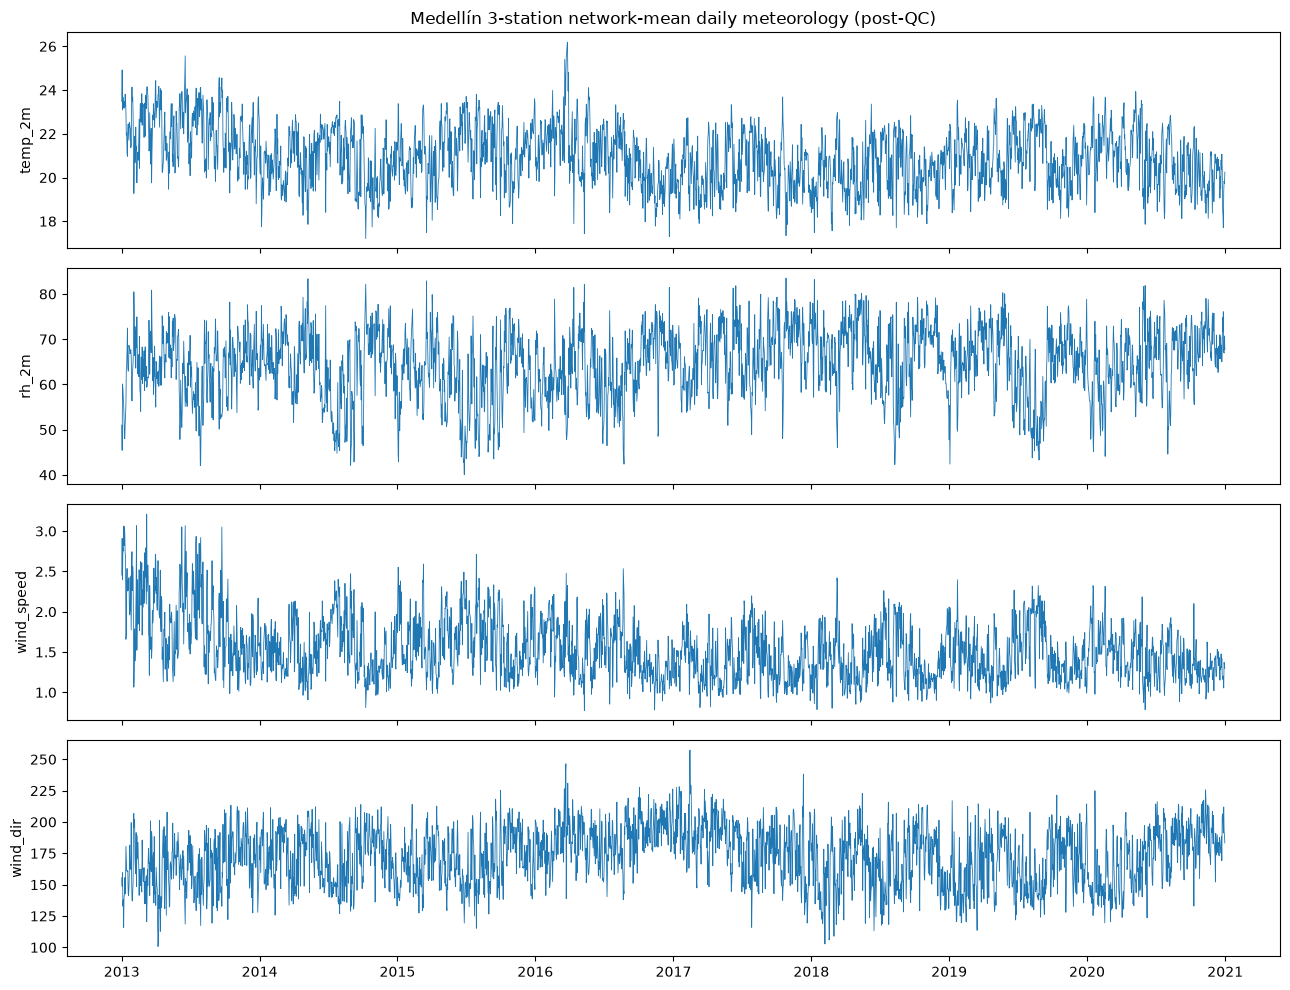

In [6]:
fig, axes = plt.subplots(4, 1, figsize=(13, 10), sharex=True)
for ax, col in zip(axes, value_cols):
    ax.plot(network_daily["date"], network_daily[col], lw=0.6)
    ax.set_ylabel(col)
axes[0].set_title("Medellín 3-station network-mean daily meteorology (post-QC)")
fig.tight_layout()
fig.savefig(FIG_DIR / "meteo_network_daily_timeseries.png", dpi=150)
plt.show()


## Save

In [7]:
network_path = OUT_DIR / "medellin_meteo_daily_clean.parquet"
network_daily.to_parquet(network_path, index=False)

completeness_path = OUT_DIR / "medellin_meteo_completeness_by_station_year.csv"
completeness.to_csv(completeness_path, index=False)

print("Saved:")
print(" ", network_path, network_daily.shape)
print(" ", completeness_path)
print("date range:", network_daily["date"].min(), "to", network_daily["date"].max())


Saved:
  /path/to/project/Data/processed/colombia/medellin/medellin_meteo_daily_clean.parquet (2919, 5)
  /path/to/project/Data/processed/colombia/medellin/medellin_meteo_completeness_by_station_year.csv
date range: 2013-01-01 00:00:00 to 2020-12-31 00:00:00
